# Classification de l'espèce d'un iris : KNN vs Arbre de décision

**Durée estimée : 1h**

## Mise en situation
Vous êtes data scientist chez **FloraLab**, un laboratoire de botanique. La direction veut un outil qui reconnaît **automatiquement l'espèce d'un iris** (Setosa, Versicolor, Virginica) à partir de quatre mesures, sans expert.


## Comment utiliser ce notebook
- Chaque section contient une **explication** (cellule texte) suivie d'une **cellule de code à compléter**.
- Les lignes `# TODO` indiquent ce qu'il faut écrire, avec un **indice** sur la fonction à utiliser.
- Les cellules **Interprétation** sont à remplir avec vos propres mots : c'est ce qui est évalué en plus du code.
- Exécutez les cellules **dans l'ordre**.

## 0. Imports et configuration
*Cette cellule est déjà remplie. Ajoutez des imports si nécessaire.*

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score, GridSearchCV
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             confusion_matrix, ConfusionMatrixDisplay, classification_report)

RANDOM_STATE = 42
sns.set_theme(style="whitegrid")

## 1. Exploration et analyse des données (EDA)

### 1.1 Chargement et structure
**But :** comprendre la forme.
**À faire :** llire le dataset, puis afficher `head()`, `shape`, `info()` et `describe()`.



In [2]:
df = sns.load_dataset("iris")
# TODO 1 : afficher head(), shape, info() et describe()
print(df.head())
print(df.shape)
print(df.info())
print(df.describe())

   sepal_length  sepal_width  petal_length  petal_width species
0           5.1          3.5           1.4          0.2  setosa
1           4.9          3.0           1.4          0.2  setosa
2           4.7          3.2           1.3          0.2  setosa
3           4.6          3.1           1.5          0.2  setosa
4           5.0          3.6           1.4          0.2  setosa
(150, 5)
<class 'pandas.DataFrame'>
RangeIndex: 150 entries, 0 to 149
Data columns (total 5 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   sepal_length  150 non-null    float64
 1   sepal_width   150 non-null    float64
 2   petal_length  150 non-null    float64
 3   petal_width   150 non-null    float64
 4   species       150 non-null    str    
dtypes: float64(4), str(1)
memory usage: 6.0 KB
None
       sepal_length  sepal_width  petal_length  petal_width
count    150.000000   150.000000    150.000000   150.000000
mean       5.843333     3.057333      3.

### 1.2 Types de variables, valeurs manquantes et doublons
**But :** repérer les problèmes de qualité.
**À faire :** identifier variables numériques et catégorielles, compter les valeurs manquantes et les doublons, vérifier qu'aucune mesure n'est négative ou nulle.


In [3]:
# TODO : types, valeurs manquantes, doublons, valeurs impossibles
categorical = df["species"]
numerique = df.drop(["species"], axis=1)
print(numerique.head())
print(categorical.head())

print("---------")
print(df.isna().sum())
print('---------------')
df.duplicated().sum()

   sepal_length  sepal_width  petal_length  petal_width
0           5.1          3.5           1.4          0.2
1           4.9          3.0           1.4          0.2
2           4.7          3.2           1.3          0.2
3           4.6          3.1           1.5          0.2
4           5.0          3.6           1.4          0.2
0    setosa
1    setosa
2    setosa
3    setosa
4    setosa
Name: species, dtype: str
---------
sepal_length    0
sepal_width     0
petal_length    0
petal_width     0
species         0
dtype: int64
---------------


np.int64(1)

### 1.3 Équilibre des classes
**But :** savoir si l'accuracy sera une métrique fiable.
**À faire :** compter le nombre de fleurs par espèce et l'afficher dans un graphique en barres.


      species   0
0      setosa  50
1  versicolor  50
2   virginica  50


<Axes: xlabel='species', ylabel='0'>

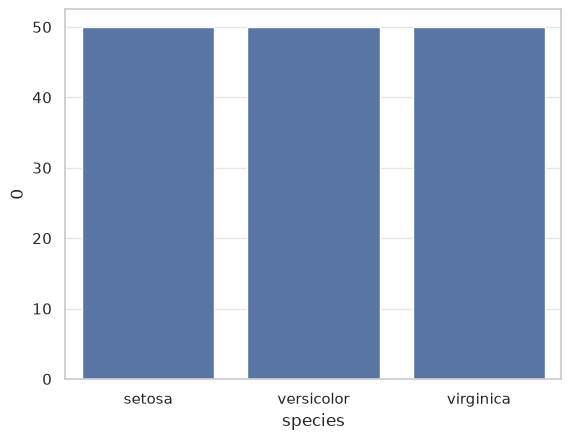

In [4]:
# TODO : value_counts + countplot ou graphique en barres
sum_per_species = df.groupby("species").size()
sum_per_species = sum_per_species.reset_index()
print(sum_per_species)

sns.barplot(data=sum_per_species, x="species", y=0)

### 1.4 Distributions des variables
**But :** comprendre la forme de chaque mesure.
**À faire :** tracer un histogramme et un boxplot pour une variable(s) numérique(s), puis un boxplot **par espèce**.


13     4.3
8      4.4
42     4.4
38     4.4
41     4.5
      ... 
122    7.7
117    7.7
118    7.7
135    7.7
131    7.9
Name: sepal_length, Length: 150, dtype: float64


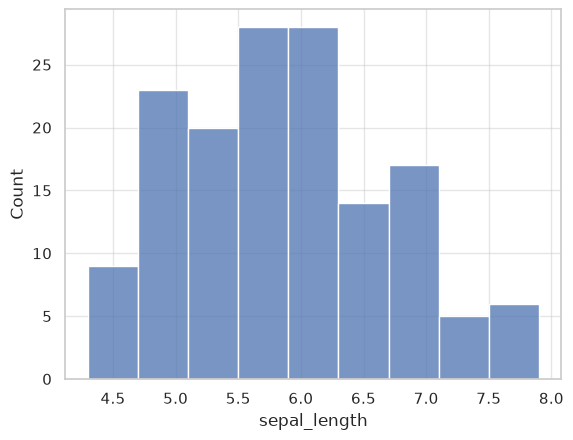

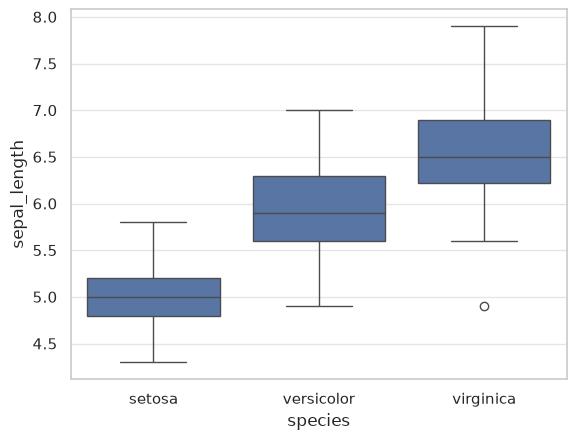

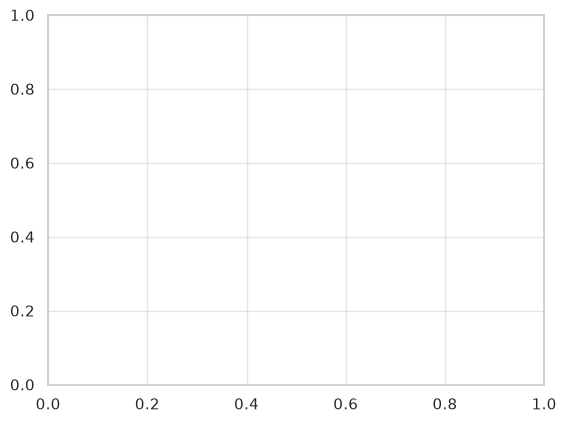

In [5]:
# TODO : histogrammes
ordered_sepal_length = df["sepal_length"].sort_values()
print(ordered_sepal_length)
sns.histplot(x=ordered_sepal_length)
plt.show()
sns.boxplot(data=df, x="species", y="sepal_length")
plt.show()
# TODO : boxplots par espèce
sns.boxplot()
plt.show()

### 1.5 Corrélations
**But :** repérer les variables redondantes.
**À faire :** calculer la matrice de corrélation des 4 mesures et l'afficher en heatmap.


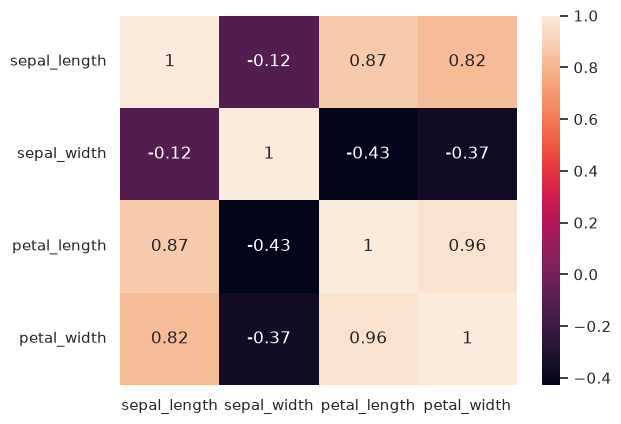

In [6]:
# TODO : matrice de corrélation + heatmap
sns.heatmap(data=numerique.corr(), annot=True)
plt.show()
plt.show()

## 2. Nettoyage des données
**But :** obtenir un jeu de données fiable.
**À faire :**
1. Traiter les valeurs manquantes (s'il y en a).
2. Supprimer les doublons **seulement si c'est justifié**.
3. Corriger les valeurs impossibles.
4. Vérifier la qualité après nettoyage (shape, doublons, valeurs manquantes).


In [7]:
# TODO : nettoyage (doublons, valeurs manquantes, incohérences)
df.drop_duplicates(inplace=True)
# TODO : vérification après nettoyage
print(df.shape)
print(df.duplicated().sum())
print(df.isna().sum())

(149, 5)
0
sepal_length    0
sepal_width     0
petal_length    0
petal_width     0
species         0
dtype: int64


**Justification de vos décisions de nettoyage :**
Didn't drop null values because there were none, as we verified it in the EDA with df.isna().sum(), but I did drop duplicated, as we discovered there being one at the EDA phase

## 3. Préparation des données
**But :** séparer ce qu'on veut prédire de ce qui sert à prédire.
**À faire :**
- Définir `y` (la cible : l'espèce).
- Définir `X` (les 4 mesures).
- Lister les variables numériques, nominales et ordinales.
- Écarter les identifiants ou variables non pertinentes.

In [8]:
# TODO : définir y
y = df["species"]
# TODO : définir X
x = df.drop(['species'], axis=1)
# TODO : créer la liste num_features (variables numériques)
num_features = df.drop(['species'], axis=1).columns
num_features

Index(['sepal_length', 'sepal_width', 'petal_length', 'petal_width'], dtype='str')

## 4. Séparation Train / Test
**But :** garder un jeu de test totalement indépendant pour l'évaluation finale.
**À faire :** séparer en 80 % / 20 % avec `random_state` et `stratify=y`, puis vérifier la répartition des espèces dans chaque ensemble.

> Le split se fait **avant** tout apprentissage de transformation (sinon : fuite de données).

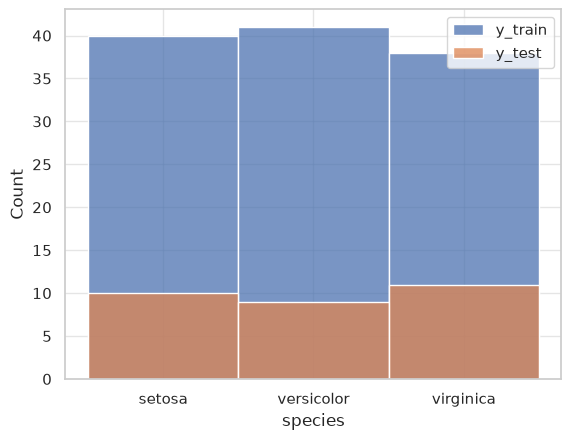

In [9]:
# TODO : X_train, X_test, y_train, y_test = train_test_split(...)
x_train, x_test, y_train, y_test = train_test_split(x, y, test_size=0.2, random_state=RANDOM_STATE)
# TODO : afficher la répartition des espèces dans y_train et y_test
sns.histplot(x=y_train)
sns.histplot(x=y_test)
plt.legend(["y_train", 'y_test'])

## 5. Prétraitement
**But :** préparer les transformations (sans encore les apprendre).
**À faire :**
- Créer un `ColumnTransformer` qui applique sur les variables numériques : `SimpleImputer(strategy='median')` puis `StandardScaler()`.
- Justifier l'absence d'`OneHotEncoder` et d'`OrdinalEncoder`.

In [10]:
# TODO : numeric_transformer = Pipeline([...])
numeric_transformer = Pipeline(
    [
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler())
    ]
)
# TODO : preprocessor = ColumnTransformer([...])
preprocessor = ColumnTransformer(
    transformers=[
        ("numeric_data", numeric_transformer, num_features),
    ]
)

### Justifier l'absence d'`OneHotEncoder` et d'`OrdinalEncoder`.
OneHotEncoder & OrdinalEncode both transform categorical values.
The dataset only has 5 columns 4 of which are numeric, and only one isn't which is the target value, and that shouldn't be altered.


## 6. Construction des pipelines
**But :** enchaîner prétraitement + modèle dans un seul objet, pour éviter toute fuite de données pendant la validation croisée.
**À faire :** créer ** le pipeline ** :
- `pipe_knn` : preprocessor + `KNeighborsClassifier()`

> Dans un `Pipeline`, donnez des noms aux étapes (par ex. `'prep'` et `'model'`) : vous en aurez besoin pour la grille d'hyperparamètres (`model__n_neighbors`).

In [11]:
# TODO : pipe_knn = Pipeline([...])
pipe_knn = Pipeline([("preprocessor", preprocessor), ("estimator", KNeighborsClassifier())])

## 7. Entraînement
**But :** obtenir une première version du modèle avec les hyperparamètres par défaut.

- **Algorithme 1 : KNN** — classe une fleur selon ses voisins les plus proches (modèle de référence).

**À faire :** entraîner le pipeline sur `X_train`, `y_train` et afficher l'accuracy sur le train.

In [12]:
# TODO : fit de pipe_knn
pipe_knn.fit(x_train, y_train)
print("--------")
# TODO : afficher le score train de chacun (.score)
score = pipe_knn.score(x_train, y_train)
print(score)

--------
0.9663865546218487


## 8. Validation croisée
**But :** estimer la performance de façon fiable.
**À faire :**
- Créer `cv = StratifiedKFold(n_splits=3, shuffle=True, random_state=RANDOM_STATE)`.
- Calculer les scores de chaque pipeline avec `cross_val_score` (métrique `accuracy`, puis `f1_macro`).
- Afficher la **moyenne** des scores.


In [13]:
# TODO : cv = StratifiedKFold(...)
cv = StratifiedKFold(n_splits=3, shuffle=True, random_state=RANDOM_STATE)
# TODO : scores accuracy et f1_macro pour pipe_knn
scores = ["accuracy", "f1_macro"]
results = {}
for score in scores:
    result = cross_val_score(pipe_knn, x_train, y_train, cv=cv, scoring=score)
    results[score] = result
# TODO : afficher moyenne
print(f'avg accuracy: {np.mean(results["accuracy"])} ')
print(f"avg f1_macro: {np.mean(results["f1_macro"])} ")

avg accuracy: 0.9414529914529915 
avg f1_macro: 0.9408085639719822 


## 9. Optimisation des hyperparamètres (GridSearchCV)
**But :** trouver les meilleurs réglages.
**À faire :** définir une grille pour ton pipeline, lancer `GridSearchCV(..., cv=cv, scoring='f1_macro')` et afficher `best_params_` et `best_score_`.

Grilles suggérées :
- **KNN** : `model__n_neighbors` (2 à 5), `model__weights` (`uniform`, `distance`), `model__p` (1, 2).
> Le préfixe `model__` correspond au nom de l'étape dans votre pipeline.
> Le GridSearch ne doit utiliser que `X_train` et `y_train`.

In [14]:
# TODO : param_grid_knn
params = {
    "estimator__n_neighbors": range(2, 5),
    "estimator__weights": ["uniform", "distance"],
    "estimator__p": (1,2)
}
# TODO : grid_knn = GridSearchCV(...) puis fit sur le train
grid_knn = GridSearchCV(cv=cv, param_grid=params, scoring="f1_macro", estimator=pipe_knn)
grid_knn.fit(x_train, y_train)
# TODO : afficher best_params_ et best_score_
print(f"best_params: {grid_knn.best_params_}")
print(f"best_score: {grid_knn.best_score_}")

best_params: {'estimator__n_neighbors': 4, 'estimator__p': 2, 'estimator__weights': 'uniform'}
best_score: 0.9488964555100842


## 10. Évaluation sur le jeu de test
**But :** mesurer la performance réelle sur des données jamais vues.
**À faire :** pour chaque meilleur modèle (`best_estimator_`) :
1. Prédire sur `X_test`.
2. Calculer accuracy, précision (macro), rappel (macro) et F1 (macro).
3. Afficher la **matrice de confusion** et le `classification_report`.
4. Donner les valeurs ( TP , FP , TN , FN) pour chaque classe .

Rappel des métriques :
- **Accuracy** : proportion de fleurs bien classées.
- **Précision** : parmi les fleurs prédites d'une espèce, combien le sont vraiment.
- **Rappel** : parmi les fleurs réellement d'une espèce, combien sont retrouvées.
- **F1 macro** : moyenne du F1 des trois espèces, à égalité.

> Le jeu de test ne doit servir qu'ici, une seule fois.

{'accuracy': 1.0, 'f1_macro': 1.0, 'precision_macro': 1.0, 'recall_macro': 1.0}
              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        10
  versicolor       1.00      1.00      1.00         9
   virginica       1.00      1.00      1.00        11

    accuracy                           1.00        30
   macro avg       1.00      1.00      1.00        30
weighted avg       1.00      1.00      1.00        30

{'TP': 20, 'TN': 0, 'FP': 0, 'FN': 0}


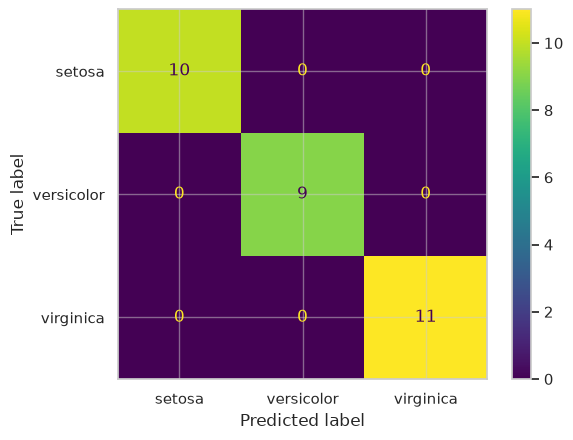

In [15]:
# TODO : best_knn = grid_knn.best_estimator_
best_knn= grid_knn.best_estimator_
# TODO : prédictions sur X_test
y_pred = best_knn.predict(x_test)
# TODO : métriques (accuracy, precision, recall, f1 avec average='macro')
scores = {
    "accuracy": accuracy_score(y_test, y_pred),
    "f1_macro": f1_score(y_test, y_pred, average="macro"),
    "precision_macro": precision_score(y_test, y_pred, average="macro"),
    "recall_macro": recall_score(y_test, y_pred, average="macro")
}
print(scores)
# TODO : matrices de confusion (ConfusionMatrixDisplay.from_estimator)
ConfusionMatrixDisplay.from_estimator(best_knn, x_test, y_test)
# TODO : classification_report
print(classification_report(y_test, y_pred))
positive_negative = {
    "TP": 20,
    "TN": 0,
    "FP": 0,
    "FN": 0
}
print(positive_negative)